In [5]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import os

run_1


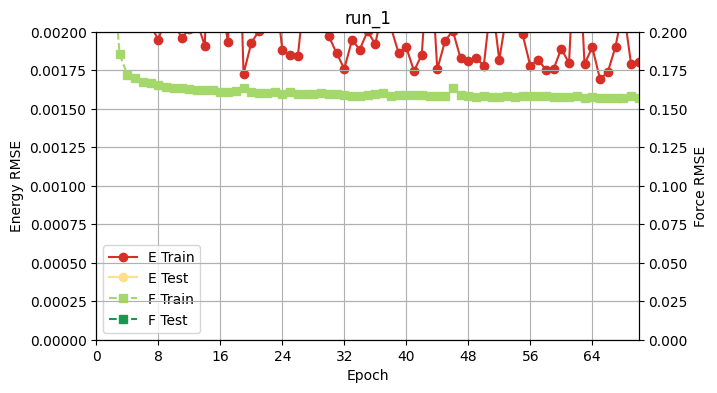

run_2


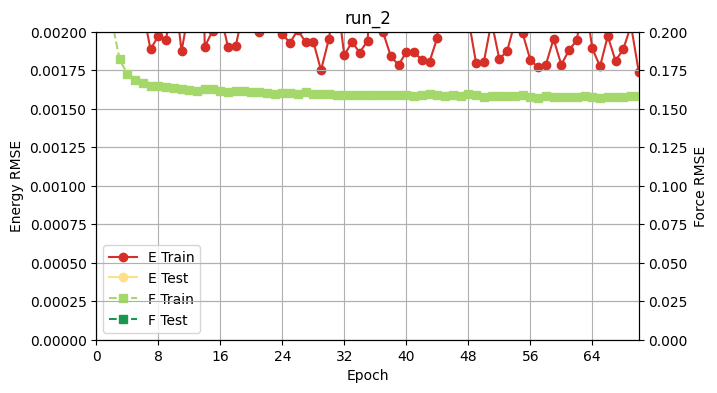

run_3


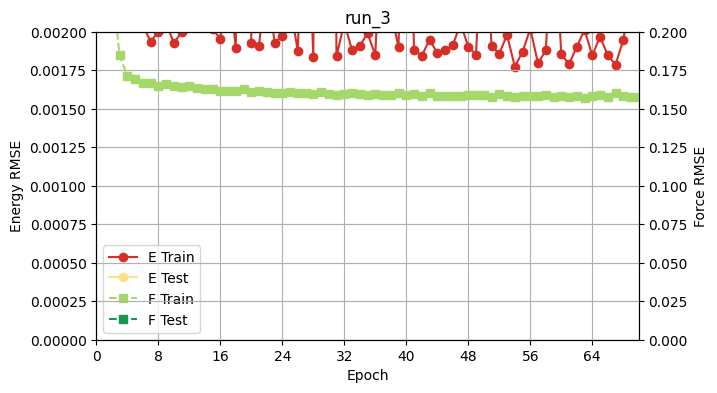

run_4


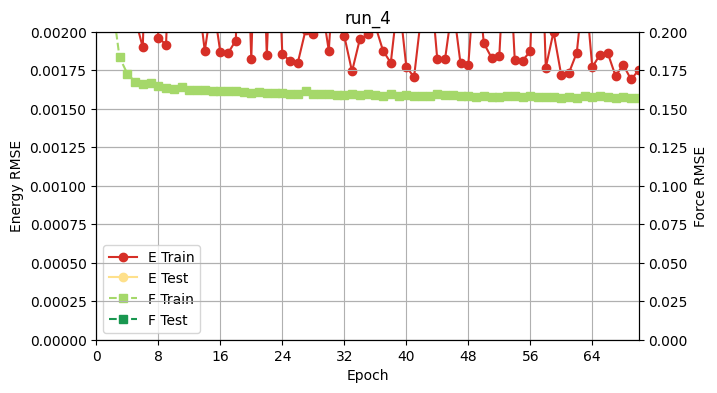

run_5


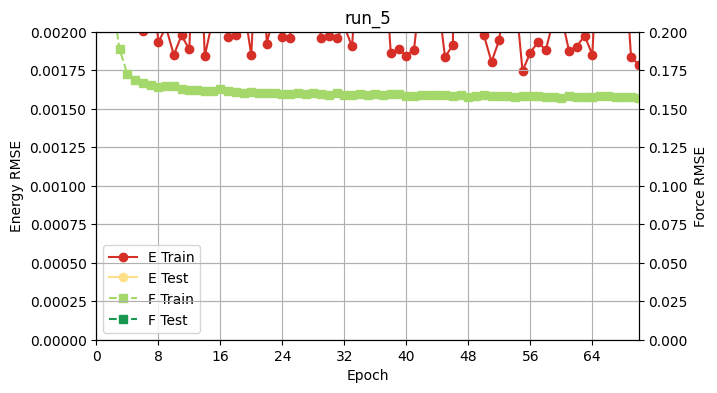

In [8]:
directory= './trial_2/'   #path of directory containing run_i folders
folders = [f for f in os.listdir(directory) if os.path.isdir(os.path.join(directory, f))]

folders = sorted(folders)


for i in folders:
    print(i)
    lines = np.loadtxt('{}{}/train/learning-curve.out'.format(directory,i))
    lines_transp = np.transpose(lines)
    
    fig, ax = plt.subplots(sharex=True, sharey=True, figsize=(7,4))
    
    plt.xlabel('Epoch')
    plt.ylabel('Energy RMSE')
    plt.grid()
    #plt.yscale("log")
    plt.ylim(0,0.002)
    plt.xlim(0,70)
    
    ax_F = ax.twinx()
    ax_F.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax_F.set_ylabel('Force RMSE')
    
    cmap = matplotlib.cm.get_cmap('RdYlGn')
    lns1 = ax.plot(lines_transp[0], lines_transp[1], ls="-", marker = "o", label="E Train", color=cmap(0.1))
    lns2 = ax.plot(lines_transp[0], lines_transp[2], ls="-", marker = "o", label="E Test", color=cmap(0.4))
    
    lns3 = ax_F.plot(lines_transp[0], lines_transp[9], ls="--", marker = "s", label="F Train", color=cmap(0.7))
    lns4 = ax_F.plot(lines_transp[0], lines_transp[10], ls="--", marker = "s", label="F Test", color=cmap(0.9))
    
    lns = lns1+lns2+lns3+lns4
    labs = [l.get_label() for l in lns]
    ax.legend(lns, labs)
    plt.grid()
    #plt.yscale("log")
    plt.ylim(0,0.2)
    plt.xlim(0,70)
    plt.title('{}'.format(i))
    plt.show()

In [12]:
#get the weights:    (set e_t=data[1], f_t=data[9] to take best weights for training_data; set e_t = data[2], f_t=data=[10] for best weights for test_data)

N=3  # set how many configurations are checked

print("best weights: put in dataset.sh")
for i, dir in enumerate(folders):
    data = np.transpose(np.loadtxt('{}{}/train/learning-curve.out'.format(directory,dir)))
    e_t=(data[1]).tolist()    #change here
    f_t=(data[9]).tolist()    #cahnge here
    
   
    
    e_t_sort=sorted(e_t)
    f_t_sort=sorted(data[9])
    
    e_best_ind = [e_t.index(e_t_sort[j]) for j in range(N)]
    #print(e_best_ind)

    f_t_e=[f_t[k] for k in e_best_ind]
    f_t_e_sort=sorted(f_t_e)
    
    e_f_best_ind= f_t.index( f_t_e_sort[0]) 
   
    print(e_f_best_ind, end=' ')
    

best weights: put in dataset.sh
66 57 61 69 70 